In [1]:
import pandas as pd
import seaborn as sns

In [7]:
# Load the dataset

df = pd.read_csv("HousePricePrediction.csv")
df.head()

,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0,208500.0
1,1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0,181500.0
2,2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0,223500.0
3,3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0,140000.0
4,4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0,250000.0


In [10]:
df.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           4
LotArea            0
LotConfig          0
BldgType           0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
Exterior1st        1
BsmtFinSF2         1
TotalBsmtSF        1
SalePrice       1459
dtype: int64

In [11]:
df.shape

(2919, 13)

In [12]:
# Rows whose SalePrice is available 
train_data = df[df["SalePrice"].notna()]

# Rows whose SalePrice is missing
prediction_data = df[df["SalePrice"].isna()]

In [13]:
train_data.shape

(1460, 13)

In [14]:
prediction_data.shape

(1459, 13)

In [15]:
# Features: Exclude SalesPrice and ID
X = train_data.drop(columns=["SalePrice", "Id"])

# Target: jis price ko predict karna hai
y = train_data["SalePrice"]

# Jinki price missing hai, unke prediction ke liye features
X_predict = prediction_data.drop(columns=["SalePrice", "Id"])

In [16]:
X_predict

,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF
1460,20,RH,11622,Inside,1Fam,6,1961,1961,VinylSd,144.0,882.0
1461,20,RL,14267,Corner,1Fam,6,1958,1958,Wd Sdng,0.0,1329.0
1462,60,RL,13830,Inside,1Fam,5,1997,1998,VinylSd,0.0,928.0
1463,60,RL,9978,Inside,1Fam,6,1998,1998,VinylSd,0.0,926.0
1464,120,RL,5005,Inside,TwnhsE,5,1992,1992,HdBoard,0.0,1280.0
...,...,...,...,...,...,...,...,...,...,...,...
2914,160,RM,1936,Inside,Twnhs,7,1970,1970,CemntBd,0.0,546.0
2915,160,RM,1894,Inside,TwnhsE,5,1970,1970,CemntBd,0.0,546.0
2916,20,RL,20000,Inside,1Fam,7,1960,1996,VinylSd,0.0,1224.0
2917,85,RL,10441,Inside,1Fam,5,1992,1992,HdBoard,0.0,912.0


In [17]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   MSSubClass    1460 non-null   int64  
 1   MSZoning      1460 non-null   str    
 2   LotArea       1460 non-null   int64  
 3   LotConfig     1460 non-null   str    
 4   BldgType      1460 non-null   str    
 5   OverallCond   1460 non-null   int64  
 6   YearBuilt     1460 non-null   int64  
 7   YearRemodAdd  1460 non-null   int64  
 8   Exterior1st   1460 non-null   str    
 9   BsmtFinSF2    1460 non-null   float64
 10  TotalBsmtSF   1460 non-null   float64
dtypes: float64(2), int64(5), str(4)
memory usage: 153.8 KB


In [18]:
X.head()

,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF
0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0
1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0
2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0
3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0
4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0


In [19]:
X.isnull().sum()

MSSubClass      0
MSZoning        0
LotArea         0
LotConfig       0
BldgType        0
OverallCond     0
YearBuilt       0
YearRemodAdd    0
Exterior1st     0
BsmtFinSF2      0
TotalBsmtSF     0
dtype: int64

In [20]:
X_encoded = pd.get_dummies(
    X,
    columns=["MSZoning", "LotConfig", "BldgType", "Exterior1st"],
    dtype=int
)

X_encoded.head()

,MSSubClass,LotArea,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF2,TotalBsmtSF,MSZoning_C (all),MSZoning_FV,MSZoning_RH,...,Exterior1st_CemntBd,Exterior1st_HdBoard,Exterior1st_ImStucc,Exterior1st_MetalSd,Exterior1st_Plywood,Exterior1st_Stone,Exterior1st_Stucco,Exterior1st_VinylSd,Exterior1st_Wd Sdng,Exterior1st_WdShing
0,60,8450,5,2003,2003,0.0,856.0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,20,9600,8,1976,1976,0.0,1262.0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
2,60,11250,5,2001,2002,0.0,920.0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,70,9550,5,1915,1970,0.0,756.0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,60,14260,5,2000,2000,0.0,1145.0,0,0,0,...,0,0,0,0,0,0,0,1,0,0


In [21]:
X_encoded.shape

(1460, 37)

In [23]:
X_predict_encoded = pd.get_dummies(
    X_predict,
    columns=["MSZoning", "LotConfig", "BldgType", "Exterior1st"],
    dtype=int
)

print(X_encoded.shape)
print(X_predict_encoded.shape)

(1460, 37)
(1459, 35)


In [24]:
missing_cols = X_encoded.columns.difference(
    X_predict_encoded.columns
)

extra_cols = X_predict_encoded.columns.difference(
    X_encoded.columns
)

print("Missing columns:", list(missing_cols))
print("Extra columns:", list(extra_cols))

Missing columns: ['Exterior1st_ImStucc', 'Exterior1st_Stone']
Extra columns: []


In [25]:
X_predict_encoded = X_predict_encoded.reindex(
    columns=X_encoded.columns,
    fill_value=0
)

In [26]:
print("Training:", X_encoded.shape)
print("Prediction:", X_predict_encoded.shape)

print(X_encoded.columns.equals(X_predict_encoded.columns))

Training: (1460, 37)
Prediction: (1459, 37)
True


In [27]:
# Train Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42
)

In [28]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1168, 37)
X_test: (292, 37)
y_train: (1168,)
y_test: (292,)


In [29]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [30]:
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Intercept: -2997834.7771382984
Coefficients: [ 8.93563659e+02  6.87795382e-01  4.33437433e+03  7.60318551e+02
  7.31067415e+02 -1.68546087e+01  8.27551834e+01 -2.08471185e+04
  7.20404144e+03  1.03914761e+04  5.96509677e+03 -2.71349583e+03
 -3.27239045e+03  1.05247097e+04 -9.87205933e+03  4.13949830e+03
 -1.51975818e+03  8.63384991e+04 -3.62485700e+04  1.43859826e+04
 -4.24226929e+04 -2.20532188e+04 -1.03181944e+04  3.95798422e+04
 -2.72057757e+04  2.81065716e+04 -1.37326495e+04  7.68925130e+03
 -2.69093239e+04  1.37407072e+04 -1.30782862e+04 -2.36008051e+04
  4.73117879e+04  8.47785369e+01 -1.45597615e+04 -4.22880842e+03
 -2.87933415e+03]


In [31]:
coefficients_df = pd.DataFrame({
    "Feature": X_encoded.columns,
    "Coefficient": model.coef_
})

coefficients_df

,Feature,Coefficient
0,MSSubClass,893.563659
1,LotArea,0.687795
2,OverallCond,4334.374333
3,YearBuilt,760.318551
4,YearRemodAdd,731.067415
5,BsmtFinSF2,-16.854609
6,TotalBsmtSF,82.755183
7,MSZoning_C (all),-20847.118477
8,MSZoning_FV,7204.041442
9,MSZoning_RH,10391.476098


In [32]:
coefficients_df.sort_values(
    by="Coefficient",
    ascending=False
)

,Feature,Coefficient
17,BldgType_1Fam,86338.499066
32,Exterior1st_Stone,47311.787938
23,Exterior1st_AsphShn,39579.842205
25,Exterior1st_BrkFace,28106.571610
19,BldgType_Duplex,14385.982612
29,Exterior1st_ImStucc,13740.707220
13,LotConfig_CulDSac,10524.709651
9,MSZoning_RH,10391.476098
27,Exterior1st_CemntBd,7689.251303
8,MSZoning_FV,7204.041442


In [33]:
y_pred = model.predict(X_test)

print("First 10 Actual Prices:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Prices:")
print(y_pred[:10])

First 10 Actual Prices:
[154500. 325000. 115000. 159000. 315500.  75500. 311500. 146000.  84500.
 135500.]

First 10 Predicted Prices:
[168844.20187044 243627.93266265 114499.46802618 157672.74928533
 254809.72691561 156499.88714206 177912.63550291 127514.41651573
 133133.47244358 149402.60951091]


In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R² Score:", r2)

MAE: 34122.85443215006
MSE: 2918458029.5854726
RMSE: 54022.75473895673
R² Score: 0.619513179654489


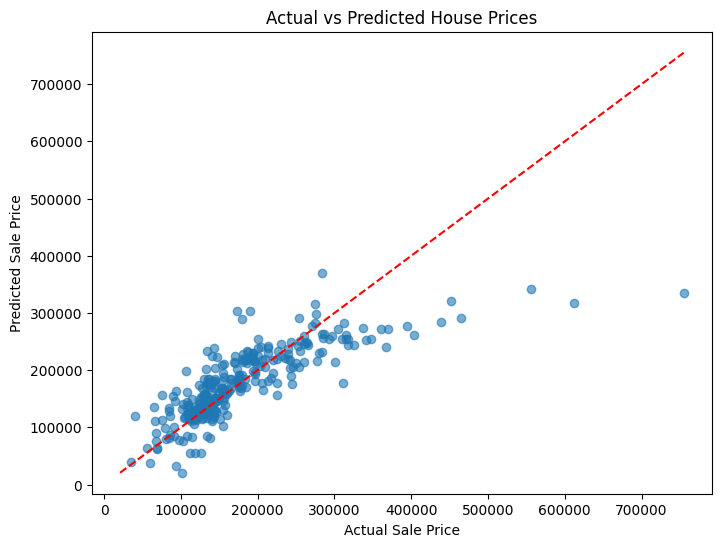

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

# Perfect prediction reference line
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    color="red",
    linestyle="--"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices")
plt.show()

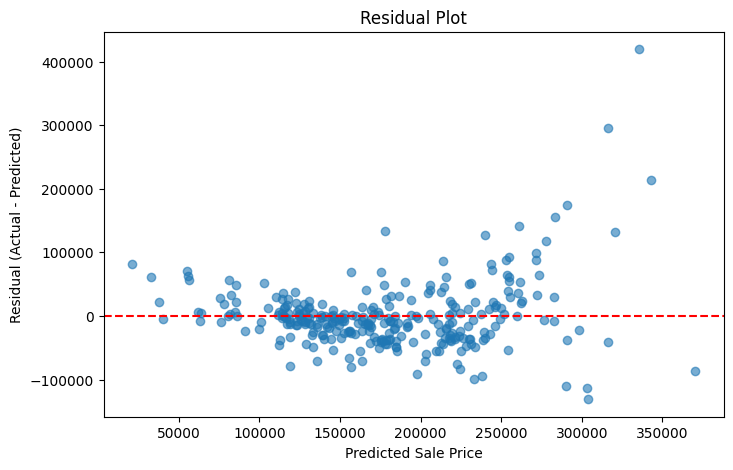

In [36]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Sale Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.show()

In [38]:
# Count missing values in prediction features
missing_values = X_predict_encoded.isnull().sum()

# Show only columns that contain missing values
print(missing_values[missing_values > 0])

BsmtFinSF2     1
TotalBsmtSF    1
dtype: int64


In [39]:
# Calculate medians from training features
bsmtfin_median = X["BsmtFinSF2"].median()
totalbsmt_median = X["TotalBsmtSF"].median()

# Fill missing values in prediction data
X_predict_encoded["BsmtFinSF2"] = (
    X_predict_encoded["BsmtFinSF2"].fillna(bsmtfin_median)
)

X_predict_encoded["TotalBsmtSF"] = (
    X_predict_encoded["TotalBsmtSF"].fillna(totalbsmt_median)
)

# Verify
print(X_predict_encoded.isnull().sum().sum())

0


In [41]:
# Predict prices for houses with missing SalePrice
missing_price_predictions = model.predict(X_predict_encoded)

# Create a copy of the original dataset
final_df = df.copy()

# Fill only the missing SalePrice values
final_df.loc[
    final_df["SalePrice"].isna(), "SalePrice"
] = missing_price_predictions

print("Missing prices before:", df["SalePrice"].isna().sum())
print("Missing prices after:", final_df["SalePrice"].isna().sum())

final_df.head()

Missing prices before: 1459
Missing prices after: 0


,Id,MSSubClass,MSZoning,LotArea,LotConfig,BldgType,OverallCond,YearBuilt,YearRemodAdd,Exterior1st,BsmtFinSF2,TotalBsmtSF,SalePrice
0,0,60,RL,8450,Inside,1Fam,5,2003,2003,VinylSd,0.0,856.0,208500.0
1,1,20,RL,9600,FR2,1Fam,8,1976,1976,MetalSd,0.0,1262.0,181500.0
2,2,60,RL,11250,Inside,1Fam,5,2001,2002,VinylSd,0.0,920.0,223500.0
3,3,70,RL,9550,Corner,1Fam,5,1915,1970,Wd Sdng,0.0,756.0,140000.0
4,4,60,RL,14260,FR2,1Fam,5,2000,2000,VinylSd,0.0,1145.0,250000.0


In [42]:
print("Final dataset shape:", final_df.shape)

print("\nMissing SalePrice values:")
print(final_df["SalePrice"].isna().sum())

print("\nPreviously missing prices — predicted examples:")
print(
    final_df.loc[
        df["SalePrice"].isna(),
        ["Id", "SalePrice"]
    ].head(10)
)

Final dataset shape: (2919, 13)

Missing SalePrice values:
0

Previously missing prices — predicted examples:
        Id      SalePrice
1460  1460  129857.642821
1461  1461  170773.275860
1462  1462  219012.851978
1463  1463  221292.646685
1464  1464  166757.424380
1465  1465  182656.251933
1466  1466  198205.146978
1467  1467  204536.846704
1468  1468  188021.698026
1469  1469  122622.014521


In [43]:
final_df.to_csv("HousePricePrediction_Completed.csv", index=False)

In [45]:
import os

print(os.path.abspath("HousePricePrediction_Completed.csv"))
print(os.path.exists("HousePricePrediction_Completed.csv"))

C:\Users\ASR\Python_Data_Science\Linear Regression\HousePricePrediction_Completed.csv
True
